In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
df = pd.read_csv('insurance_data.csv')

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


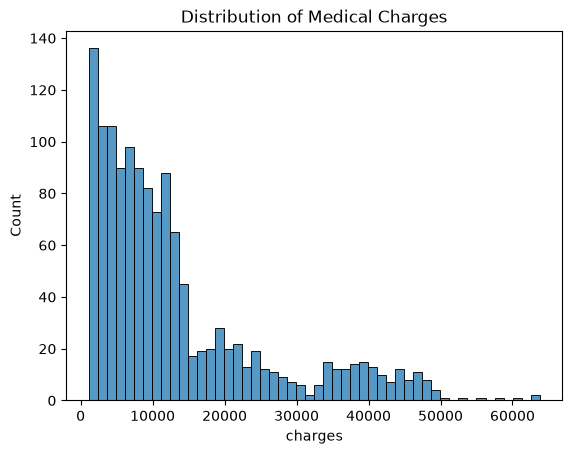

In [4]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)
for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.head()
df.isnull().sum()
sns.histplot(df.charges, bins=50)
plt.title("Distribution of Medical Charges")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

# Split off 20% for the Test set
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

# Split the remaining 80% into Train (60%) and Validation (20%)
# (0.25 of 0.80 = 0.20)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Reset indexes for neatness
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print("Train set size:", len(df_train))
print("Validation set size:", len(df_val))
print("Test set size:", len(df_test))

Train set size: 802
Validation set size: 268
Test set size: 268


In [6]:
y_train = np.log1p(df_train.charges.values)
y_val = np.log1p(df_val.charges.values)
y_test = np.log1p(df_test.charges.values)

# Delete targets from features so the model doesn't cheat
del df_train['charges']
del df_val['charges']
del df_test['charges']

In [7]:
from sklearn.feature_extraction import DictVectorizer

# Convert our dataframes into dictionaries
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')

# Initialize the vectorizer and transform the data
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Check the new features (Notice how it automatically created smoker=yes, smoker=no, etc.)
print(dv.get_feature_names_out())

['age' 'bmi' 'children' 'region=northeast' 'region=northwest'
 'region=southeast' 'region=southwest' 'sex=female' 'sex=male' 'smoker=no'
 'smoker=yes']


In [8]:
from sklearn.metrics import mean_squared_error

def rmse(y_true, y_pred):
    # Calculates the Mean Squared Error, then takes the square root
    return np.sqrt(mean_squared_error(y_true, y_pred))

In [9]:
from sklearn.linear_model import Ridge

# Initialize the model (alpha is our regularization parameter 'r')
model_lr = Ridge(alpha=1.0, random_state=1)

# Train the model using the Training data
model_lr.fit(X_train, y_train)

# Make predictions on the Validation data
y_pred_lr = model_lr.predict(X_val)

# Check the score
score_lr = rmse(y_val, y_pred_lr)
print("Baseline Linear Regression RMSE:", round(score_lr, 3))

Baseline Linear Regression RMSE: 0.446


In [10]:
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest (n_estimators = 100 trees)
model_rf = RandomForestRegressor(n_estimators=100, random_state=1)

# Train the model
model_rf.fit(X_train, y_train)

# Make predictions
y_pred_rf = model_rf.predict(X_val)

# Check the score
score_rf = rmse(y_val, y_pred_rf)
print("Random Forest RMSE:", round(score_rf, 3))

Random Forest RMSE: 0.413


In [11]:
# List of different depths to try
depths = [5, 10, 15, 20, 25]

for d in depths:
    # Initialize model with the current depth
    rf = RandomForestRegressor(n_estimators=100, max_depth=d, random_state=1)
    
    # Train
    rf.fit(X_train, y_train)
    
    # Predict and Score
    y_pred = rf.predict(X_val)
    score = rmse(y_val, y_pred)
    
    print(f"Depth: {d} | RMSE: {round(score, 3)}")

Depth: 5 | RMSE: 0.395
Depth: 10 | RMSE: 0.411
Depth: 15 | RMSE: 0.413
Depth: 20 | RMSE: 0.413
Depth: 25 | RMSE: 0.413


In [ ]:
# 1. Prepare the full training dataset (Train + Validation combined)
y_full_train = np.log1p(df_full_train.charges.values)
del df_full_train['charges']

full_train_dicts = df_full_train.to_dict(orient='records')

# Fit the DictVectorizer on the full training data
X_full_train = dv.fit_transform(full_train_dicts)

# 2. Train the FINAL model using our best parameter: max_depth=5
final_model = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=1)
final_model.fit(X_full_train, y_full_train)

# 3. The Ultimate Test: Evaluate on the Test set (data the model has NEVER seen!)
test_dicts = df_test.to_dict(orient='records')
X_test = dv.transform(test_dicts)
y_pred_test = final_model.predict(X_test)

final_score = rmse(y_test, y_pred_test)
print(f"Final Test RMSE: {round(final_score, 3)}")

Final Test RMSE: 0.351
